# Chapter 3.2 - Chapter 3.7

In this notebook, we demonstrate how to construct various neural networks, ranging from the canonical fully connected neural networks to transformers. Note that the focus here is on network architecture, so we will not adjust hyperparameters. We will use a fixed validation set with early stop to control for overfitting problem. In Chapter 4, we demonstrate how to perform cross-valiation to select the most appropriate hyperparameters. 

In [1]:
import os 
import sys
current_dir = os.path.dirname(os.path.abspath("__file__"))
project_dir = os.path.dirname(current_dir)
sys.path.append(project_dir)

import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt 
from Utilis.early_stopper import EarlyStopping

torch.manual_seed(42)
np.random.seed(42)

In [2]:
def train_model(model, X_train, y_train, X_val, y_val, X_test, 
                savepath, epochs=5, lr=1e-3, batch_size=32, patience=5):
    optimizer = optim.Adam(model.parameters(), lr=lr)
    criterion = nn.MSELoss()

    dataset = torch.utils.data.TensorDataset(X_train, y_train)
    dataloader = torch.utils.data.DataLoader(dataset,
                                             batch_size=batch_size,
                                             shuffle=True)
    
    early_stopper = EarlyStopping(savepath=savepath, patience=patience, min_delta=1e-4, verbose=True)

    for epoch in range(epochs):
        model.train()
        epoch_loss = 0.0

        for batch_X, batch_y in dataloader:
            optimizer.zero_grad()
            out = model(batch_X)
            loss = criterion(out, batch_y)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item() * batch_X.size(0)

        epoch_loss /= len(dataloader.dataset)
        model.eval()
        with torch.no_grad():
            y_pred_val = model(X_val)
            val_loss = criterion(y_pred_val, y_val).item()

        print(f"Epoch {epoch+1}/{epochs}, "
              f"Train loss: {epoch_loss:.4f}, "
              f"Validation loss: {val_loss:.4f}")
        
        early_stopper(model, val_loss)
        if early_stopper.early_stop:
            print("Early stopping triggered!")
            break
    
    model.load_state_dict(torch.load(savepath))
    model.eval()
    y_pred_test = model(X_test)    
    return model, y_pred_test

In [3]:
class MLP(nn.Module):
    def __init__(self, seq_length, n_features):
        super(MLP, self).__init__()
        self.flat_dim = seq_length * n_features
        self.net = nn.Sequential(
            nn.Flatten(),                   # (batch, seq_length*n_features)
            nn.Linear(self.flat_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1)                
        )
    def forward(self, x):
        return self.net(x)

class CNN(nn.Module):
    def __init__(self, n_features, out_channels=32):
        super(CNN, self).__init__()
        # in_channels = n_features, kernel_size=3, padding=1 
        self.conv = nn.Sequential(
            nn.Conv1d(in_channels=n_features,
                      out_channels=out_channels,
                      kernel_size=3,
                      padding=1),
            nn.ReLU(),
            nn.Conv1d(out_channels, out_channels,
                      kernel_size=3,
                      padding=1),
            nn.ReLU()
        )
        self.pool = nn.AdaptiveAvgPool1d(1)  
        self.fc   = nn.Linear(out_channels, 1)

    def forward(self, x):
        # x: (batch, seq_length, n_features)
        x = x.permute(0, 2, 1)  
        x = self.conv(x)
        x = self.pool(x)        # shape: (batch, out_channels, 1)
        x = x.squeeze(-1)       # (batch, out_channels)
        x = self.fc(x)          # (batch,1)
        return x

class WaveNetLike(nn.Module):
    def __init__(self, n_features, out_channels=32,
                 kernel_size=2, dilation_depth=4):
        super(WaveNetLike, self).__init__()
        layers = []
        in_channels = n_features
        for d in range(dilation_depth):
            dilation_rate = 2 ** d
            padding = (kernel_size - 1) * dilation_rate
            conv = nn.Conv1d(
                in_channels=in_channels,
                out_channels=out_channels,
                kernel_size=kernel_size,
                dilation=dilation_rate,
                padding=padding
            )
            layers.append(conv)
            in_channels = out_channels

        self.convs = nn.ModuleList(layers)
        self.activation = nn.ReLU()
        self.pool = nn.AdaptiveAvgPool1d(1)
        self.fc   = nn.Linear(out_channels, 1)

    def forward(self, x):
        # x: (batch, seq_length, n_features)
        x = x.permute(0, 2, 1)  # (batch, n_features, seq_length)

        for conv in self.convs:
            x = conv(x)
            x = self.activation(x)

        x = self.pool(x)        # (batch, out_channels, 1)
        x = x.squeeze(-1)       # (batch, out_channels)
        x = self.fc(x)          # (batch,1)
        return x

class LSTMModel(nn.Module):
    def __init__(self, n_features, hidden_size=64):
        super(LSTMModel, self).__init__()
        self.lstm = nn.LSTM(input_size=n_features,
                            hidden_size=hidden_size,
                            batch_first=True)
        self.fc = nn.Sequential(
            nn.Linear(hidden_size, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )
    def forward(self, x):
        # x: (batch, seq_length, n_features)
        output, (h_n, c_n) = self.lstm(x)
        # output: (batch, seq_length, hidden_size)
        last_output = output[:, -1, :]  # (batch, hidden_size)
        return self.fc(last_output)

class TransformerModel(nn.Module):
    def __init__(self, seq_length, n_features, d_model=64, nhead=4, num_layers=2):
        super(TransformerModel, self).__init__()
        self.d_model = d_model

        self.input_fc = nn.Linear(n_features, d_model)
        self.pos_embedding = nn.Parameter(
            torch.randn(1, seq_length, d_model)
        )

        # TransformerEncoder
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=128,
            batch_first=True
        )
        self.transformer_encoder = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers
        )
        self.pool = nn.AdaptiveAvgPool1d(1)
        self.fc = nn.Linear(d_model, 1)

    def forward(self, x):
        # x: (batch, seq_length, n_features)
        x = self.input_fc(x)  # (batch, seq_length, d_model)

        seq_len = x.size(1)
        x = x + self.pos_embedding[:, :seq_len, :]
        x = self.transformer_encoder(x)  # (batch, seq_length, d_model)

        # Global Average Pooling over seq_length
        x = x.permute(0, 2, 1)
        x = self.pool(x)  # (batch, d_model, 1)
        x = x.squeeze(-1) # (batch, d_model)

        x = self.fc(x)    # (batch, 1)
        return x

I here simiulate some data to perform a regression problem. The x inputs have dimension of (batch_samples, time look-back windows, feature numbers).

In [4]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")
N = 2000           
seq_length = 20    
n_features = 3    

# X: (N, seq_length, n_features)
X_np = np.random.randn(N, seq_length, n_features)
noise = 0.1 * np.random.randn(N)
y_np = 2 * X_np[:, -1, 0] + 3 * X_np[:, -1, 1] - 1.5 * X_np[:, -1, 2] + noise
y_np = y_np.reshape(-1, 1)  # shape (N,1)

split_index_val = int(N * 0.6)
split_index_test = int(N * 0.8)

X_train_np = X_np[:split_index_val]
y_train_np = y_np[:split_index_val]
X_val_np = X_np[split_index_val:split_index_test]
y_val_np = y_np[split_index_val:split_index_test]
X_test_np  = X_np[split_index_test:]
y_test_np  = y_np[split_index_test:]

X_train = torch.tensor(X_train_np, dtype=torch.float32).to(device)
y_train = torch.tensor(y_train_np, dtype=torch.float32).to(device)
X_val = torch.tensor(X_val_np, dtype=torch.float32).to(device)
y_val = torch.tensor(y_val_np, dtype=torch.float32).to(device)
X_test  = torch.tensor(X_test_np,  dtype=torch.float32).to(device)
y_test  = torch.tensor(y_test_np,  dtype=torch.float32).to(device)

print("Train X shape:", X_train.shape)
print("Train y shape:", y_train.shape)
print("Val X shape:", X_val.shape)
print("Val y shape:", y_val.shape)
print("Test  X shape:", X_test.shape)
print("Test  y shape:", y_test.shape)

Using device: cpu
Train X shape: torch.Size([1200, 20, 3])
Train y shape: torch.Size([1200, 1])
Val X shape: torch.Size([400, 20, 3])
Val y shape: torch.Size([400, 1])
Test  X shape: torch.Size([400, 20, 3])
Test  y shape: torch.Size([400, 1])


In [5]:
mlp_model = MLP(seq_length, n_features).to(device)
mlp_model, y_pred_mlp = train_model(mlp_model, X_train, y_train, X_val, y_val, X_test, epochs=40, savepath='model/best_mlp')

Epoch 1/40, Train loss: 15.9566, Validation loss: 14.3069
Epoch 2/40, Train loss: 13.8909, Validation loss: 10.6989
Validation loss improved. Resetting counter.
Epoch 3/40, Train loss: 7.2506, Validation loss: 3.3229
Validation loss improved. Resetting counter.
Epoch 4/40, Train loss: 1.3336, Validation loss: 0.6933
Validation loss improved. Resetting counter.
Epoch 5/40, Train loss: 0.4361, Validation loss: 0.4435
Validation loss improved. Resetting counter.
Epoch 6/40, Train loss: 0.2783, Validation loss: 0.3741
Validation loss improved. Resetting counter.
Epoch 7/40, Train loss: 0.1986, Validation loss: 0.3386
Validation loss improved. Resetting counter.
Epoch 8/40, Train loss: 0.1511, Validation loss: 0.3056
Validation loss improved. Resetting counter.
Epoch 9/40, Train loss: 0.1185, Validation loss: 0.2812
Validation loss improved. Resetting counter.
Epoch 10/40, Train loss: 0.0961, Validation loss: 0.2673
Validation loss improved. Resetting counter.
Epoch 11/40, Train loss: 0.080

Epoch 12/40, Train loss: 0.0673, Validation loss: 0.2351
Validation loss improved. Resetting counter.
Epoch 13/40, Train loss: 0.0570, Validation loss: 0.2278
Validation loss improved. Resetting counter.
Epoch 14/40, Train loss: 0.0477, Validation loss: 0.2191
Validation loss improved. Resetting counter.
Epoch 15/40, Train loss: 0.0421, Validation loss: 0.2117
Validation loss improved. Resetting counter.
Epoch 16/40, Train loss: 0.0371, Validation loss: 0.2102
Validation loss improved. Resetting counter.
Epoch 17/40, Train loss: 0.0324, Validation loss: 0.2001
Validation loss improved. Resetting counter.
Epoch 18/40, Train loss: 0.0285, Validation loss: 0.2000
No improvement in validation loss. Counter: 1/5
Epoch 19/40, Train loss: 0.0245, Validation loss: 0.1872
Validation loss improved. Resetting counter.
Epoch 20/40, Train loss: 0.0221, Validation loss: 0.1943
No improvement in validation loss. Counter: 1/5
Epoch 21/40, Train loss: 0.0198, Validation loss: 0.1877
No improvement in v

Epoch 23/40, Train loss: 0.0158, Validation loss: 0.1843
Validation loss improved. Resetting counter.
Epoch 24/40, Train loss: 0.0146, Validation loss: 0.1814
Validation loss improved. Resetting counter.
Epoch 25/40, Train loss: 0.0121, Validation loss: 0.1802
Validation loss improved. Resetting counter.
Epoch 26/40, Train loss: 0.0111, Validation loss: 0.1810
No improvement in validation loss. Counter: 1/5
Epoch 27/40, Train loss: 0.0103, Validation loss: 0.1810
No improvement in validation loss. Counter: 2/5
Epoch 28/40, Train loss: 0.0095, Validation loss: 0.1794
Validation loss improved. Resetting counter.
Epoch 29/40, Train loss: 0.0079, Validation loss: 0.1754
Validation loss improved. Resetting counter.
Epoch 30/40, Train loss: 0.0075, Validation loss: 0.1806
No improvement in validation loss. Counter: 1/5
Epoch 31/40, Train loss: 0.0068, Validation loss: 0.1753
No improvement in validation loss. Counter: 2/5
Epoch 32/40, Train loss: 0.0061, Validation loss: 0.1781
No improvemen

Epoch 35/40, Train loss: 0.0047, Validation loss: 0.1764
No improvement in validation loss. Counter: 1/5
Epoch 36/40, Train loss: 0.0044, Validation loss: 0.1776
No improvement in validation loss. Counter: 2/5
Epoch 37/40, Train loss: 0.0038, Validation loss: 0.1743
No improvement in validation loss. Counter: 3/5
Epoch 38/40, Train loss: 0.0033, Validation loss: 0.1753
No improvement in validation loss. Counter: 4/5
Epoch 39/40, Train loss: 0.0030, Validation loss: 0.1747
No improvement in validation loss. Counter: 5/5
Early stopping triggered!


In [6]:
cnn_model = CNN(n_features=3).to(device)
cnn_model, y_pred_cnn = train_model(cnn_model, X_train, y_train, X_val, y_val, X_test, epochs=40, savepath='model/best_cnn')

Epoch 1/40, Train loss: 16.1262, Validation loss: 15.0560


Epoch 2/40, Train loss: 16.0447, Validation loss: 14.9614
Validation loss improved. Resetting counter.


Epoch 3/40, Train loss: 15.9041, Validation loss: 14.7915
Validation loss improved. Resetting counter.


Epoch 4/40, Train loss: 15.6995, Validation loss: 14.4765
Validation loss improved. Resetting counter.


Epoch 5/40, Train loss: 15.3622, Validation loss: 14.4981
No improvement in validation loss. Counter: 1/5


Epoch 6/40, Train loss: 15.3279, Validation loss: 13.9029
Validation loss improved. Resetting counter.


... (30 outputs left out)

Epoch 37/40, Train loss: 4.6976, Validation loss: 4.8134
Validation loss improved. Resetting counter.


Epoch 38/40, Train loss: 4.7165, Validation loss: 4.9016
No improvement in validation loss. Counter: 1/5


Epoch 39/40, Train loss: 4.5466, Validation loss: 4.5581
Validation loss improved. Resetting counter.


Epoch 40/40, Train loss: 4.3631, Validation loss: 4.4638
Validation loss improved. Resetting counter.


In [7]:
wavenet_model = WaveNetLike(n_features=3).to(device)
wavenet_model, y_pred_wavenet = train_model(wavenet_model, X_train, y_train, X_val, y_val, X_test, epochs=40, savepath='model/best_wavenet')

Epoch 1/40, Train loss: 16.1240, Validation loss: 15.0843


Epoch 2/40, Train loss: 16.0722, Validation loss: 14.9099
Validation loss improved. Resetting counter.


Epoch 3/40, Train loss: 15.5656, Validation loss: 14.0090
Validation loss improved. Resetting counter.


Epoch 4/40, Train loss: 14.2402, Validation loss: 12.1374
Validation loss improved. Resetting counter.


Epoch 5/40, Train loss: 12.7654, Validation loss: 10.4965
Validation loss improved. Resetting counter.


Epoch 6/40, Train loss: 10.4833, Validation loss: 7.5672
Validation loss improved. Resetting counter.


... (30 outputs left out)

Epoch 37/40, Train loss: 0.1128, Validation loss: 0.1043
Validation loss improved. Resetting counter.


Epoch 38/40, Train loss: 0.1132, Validation loss: 0.1336
No improvement in validation loss. Counter: 1/5


Epoch 39/40, Train loss: 0.1569, Validation loss: 0.1226
No improvement in validation loss. Counter: 2/5


Epoch 40/40, Train loss: 0.1191, Validation loss: 0.2517
No improvement in validation loss. Counter: 3/5


In [8]:
lstm_model = LSTMModel(n_features=3).to(device)
lstm_model, y_pred_lstm = train_model(lstm_model, X_train, y_train, X_val, y_val, X_test, epochs=40, savepath='model/best_lstm')

Epoch 1/40, Train loss: 15.8182, Validation loss: 14.0293
Epoch 2/40, Train loss: 11.8408, Validation loss: 6.2013
Validation loss improved. Resetting counter.


Epoch 3/40, Train loss: 2.6836, Validation loss: 0.3100
Validation loss improved. Resetting counter.
Epoch 4/40, Train loss: 0.2171, Validation loss: 0.0789
Validation loss improved. Resetting counter.


Epoch 5/40, Train loss: 0.1113, Validation loss: 0.0424
Validation loss improved. Resetting counter.
Epoch 6/40, Train loss: 0.0623, Validation loss: 0.0287
Validation loss improved. Resetting counter.


Epoch 7/40, Train loss: 0.0446, Validation loss: 0.0280
Validation loss improved. Resetting counter.
Epoch 8/40, Train loss: 0.0361, Validation loss: 0.0185
Validation loss improved. Resetting counter.


Epoch 9/40, Train loss: 0.0336, Validation loss: 0.0179
Validation loss improved. Resetting counter.
Epoch 10/40, Train loss: 0.0256, Validation loss: 0.0155
Validation loss improved. Resetting counter.


Epoch 11/40, Train loss: 0.0237, Validation loss: 0.0143
Validation loss improved. Resetting counter.
Epoch 12/40, Train loss: 0.0217, Validation loss: 0.0159
No improvement in validation loss. Counter: 1/5


... (3 outputs left out)

Epoch 19/40, Train loss: 0.0164, Validation loss: 0.0133
No improvement in validation loss. Counter: 3/5
Epoch 20/40, Train loss: 0.0155, Validation loss: 0.0115
Validation loss improved. Resetting counter.


Epoch 21/40, Train loss: 0.0169, Validation loss: 0.0147
No improvement in validation loss. Counter: 1/5
Epoch 22/40, Train loss: 0.0158, Validation loss: 0.0251
No improvement in validation loss. Counter: 2/5


Epoch 23/40, Train loss: 0.0163, Validation loss: 0.0274
No improvement in validation loss. Counter: 3/5
Epoch 24/40, Train loss: 0.0161, Validation loss: 0.0118
No improvement in validation loss. Counter: 4/5


Epoch 25/40, Train loss: 0.0144, Validation loss: 0.0154
No improvement in validation loss. Counter: 5/5
Early stopping triggered!


In [9]:
transformer_model = TransformerModel(seq_length, n_features).to(device)
transformer_model, y_pred_transformer = train_model(transformer_model, X_train, y_train, X_val, y_val, X_test, epochs=40, savepath='model/best_transformer')

Epoch 1/40, Train loss: 14.2274, Validation loss: 4.2704


Epoch 2/40, Train loss: 2.5878, Validation loss: 0.9691
Validation loss improved. Resetting counter.


Epoch 3/40, Train loss: 0.9266, Validation loss: 0.3097
Validation loss improved. Resetting counter.


Epoch 4/40, Train loss: 0.4400, Validation loss: 0.1542
Validation loss improved. Resetting counter.


Epoch 5/40, Train loss: 0.2662, Validation loss: 0.0999
Validation loss improved. Resetting counter.


Epoch 6/40, Train loss: 0.1866, Validation loss: 0.0541
Validation loss improved. Resetting counter.


... (9 outputs left out)

Epoch 16/40, Train loss: 0.0600, Validation loss: 0.0205
No improvement in validation loss. Counter: 2/5


Epoch 17/40, Train loss: 0.0524, Validation loss: 0.0535
No improvement in validation loss. Counter: 3/5


Epoch 18/40, Train loss: 0.0514, Validation loss: 0.0406
No improvement in validation loss. Counter: 4/5


Epoch 19/40, Train loss: 0.0488, Validation loss: 0.0320
No improvement in validation loss. Counter: 5/5
Early stopping triggered!


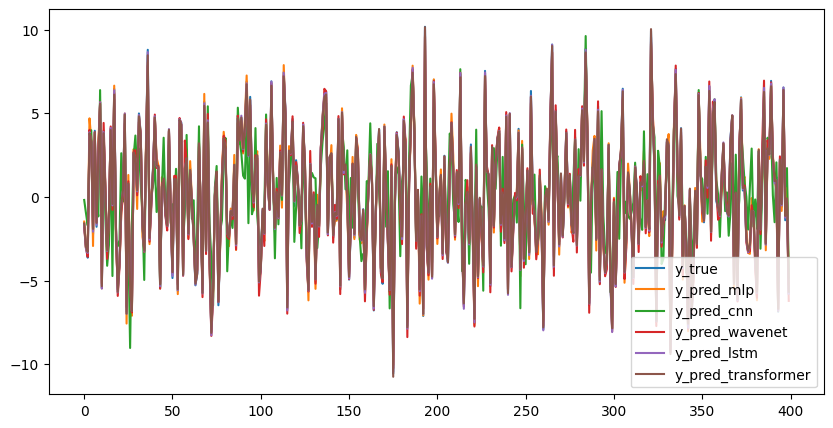

In [10]:
plt.figure(figsize=(10,5))
plt.plot(y_test, label='y_true')
plt.plot(y_pred_mlp.detach().numpy(), label='y_pred_mlp')
plt.plot(y_pred_cnn.detach().numpy(), label='y_pred_cnn')
plt.plot(y_pred_wavenet.detach().numpy(), label='y_pred_wavenet')
plt.plot(y_pred_lstm.detach().numpy(), label='y_pred_lstm')
plt.plot(y_pred_transformer.detach().numpy(), label='y_pred_transformer')
plt.legend()